# 01 · Çoklu Lineer Regresyon (Multiple Linear Regression)

## Nedir?
**Basit** lineer regresyon tek değişkenle tahmin yapar: $y = \beta_0 + \beta_1 x$

**Çoklu** lineer regresyon **birden fazla bağımsız değişken** kullanarak sürekli bir hedefi tahmin eder:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

| Sembol | Anlamı |
|---|---|
| $\hat{y}$ | Tahmin edilen değer (örn. ev fiyatı) |
| $\beta_0$ | Sabit terim (intercept) |
| $\beta_i$ | $x_i$ **1 birim artarsa, diğerleri sabitken** y'deki ortalama değişim |

**Örnek:** `fiyat = 50.000 + 3.000·m² + 20.000·oda − 1.500·yaş` → diğer her şey sabitken 1 m² büyüme fiyatı ortalama **3.000 TL** artırır.

## Nasıl öğrenir? (En Küçük Kareler – OLS)
$$\min_\beta \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \quad\Rightarrow\quad \boldsymbol{\beta} = (X^TX)^{-1}X^Ty$$
Büyük verilerde **Gradyan İnişi** ile iteratif çözülür.

## Varsayımlar

| Varsayım | Kontrol yöntemi | İhlal edilirse |
|---|---|---|
| **Doğrusallık** | Scatter plot, artık grafiği | Polinom/log dönüşüm, ağaç modelleri |
| **Hataların bağımsızlığı** | Durbin-Watson (≈2 iyi) | Zaman serisi modelleri |
| **Hataların normalliği** | Q-Q plot | log(y) dönüşümü |
| **Sabit varyans** | Artık vs tahmin grafiği | log(y), robust standart hata |
| **Çoklu doğrusallık yok** | **VIF** (>5–10 sorunlu) | Değişken çıkar, Ridge, PCA |

## Makine öğrenmesinde ne işe yarar?
- 🏠 Fiyat tahmini · 📈 Satış/talep tahmini · 🏥 Sağlık skorları
- 🔍 **Etki analizi:** Hangi faktör sonucu ne kadar etkiliyor?
- 📏 **Baseline model:** Karmaşık modeller önce bunu geçebilmeli.

**Avantaj:** hızlı, yorumlanabilir, az veriyle çalışır. **Dezavantaj:** doğrusal olmayanı yakalayamaz, aykırı değerlere ve çoklu doğrusallığa duyarlı.

## 1. Kütüphaneler

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
%matplotlib inline

import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

## 2. Veri: Sentetik ev fiyatı verisi
Gerçek katsayıları **bildiğimiz** bir veri üretiyoruz; böylece modelin onları doğru bulup bulmadığını kontrol edebiliriz.

In [3]:
rng = np.random.default_rng(42)
n = 1000

df = pd.DataFrame({
    "m2":        rng.uniform(50, 250, n),
    "oda":       rng.integers(1, 6, n),
    "yas":       rng.uniform(0, 40, n),
    "merkez_km": rng.uniform(1, 30, n),
    "semt":      rng.choice(["Kadıköy", "Beşiktaş", "Esenyurt"], n),
})
semt_etkisi = df["semt"].map({"Kadıköy": 300_000, "Beşiktaş": 400_000, "Esenyurt": 0})

# Gerçek ilişki: fiyat = 200k + 15k*m2 + 50k*oda - 8k*yas - 20k*merkez_km + semt + gürültü
df["fiyat"] = (200_000 + 15_000*df["m2"] + 50_000*df["oda"]
               - 8_000*df["yas"] - 20_000*df["merkez_km"]
               + semt_etkisi + rng.normal(0, 150_000, n))

# Gerçek hayatı taklit: 30 satırda bina yaşı eksik
df.loc[rng.choice(n, 30, replace=False), "yas"] = np.nan
df.head()

,m2,oda,yas,merkez_km,semt,fiyat
0,204.791210,5,26.874168,1.982456,Esenyurt,3.111136e+06
1,137.775688,1,38.423479,20.807434,Beşiktaş,1.768600e+06
2,221.719584,2,14.836493,28.564392,Esenyurt,3.138703e+06
3,189.473606,3,17.003271,25.045364,Beşiktaş,3.318538e+06
4,68.835470,4,32.484918,9.038746,Beşiktaş,1.320515e+06


In [18]:
print("Boyut:", df.shape)
print("\nEksik değerler:\n", df.isna().sum())
print("\nTekrarlı satır:", df.duplicated().sum())
df.describe().round(1).T

Boyut: (1000, 6)

Eksik değerler:
 m2            0
oda           0
yas          30
merkez_km     0
semt          0
fiyat         0
dtype: int64

Tekrarlı satır: 0


,count,mean,std,min,25%,50%,75%,max
m2,1000.0,149.4,58.3,50.2,98.1,149.0,201.8,249.8
oda,1000.0,3.0,1.4,1.0,2.0,3.0,4.0,5.0
yas,970.0,20.0,11.6,0.0,9.9,19.7,30.3,40.0
merkez_km,1000.0,15.4,8.5,1.0,8.1,15.7,22.6,30.0
fiyat,1000.0,2359463.0,925273.5,91659.4,1597405.9,2355917.6,3107626.5,4397729.4


**Yorum:** 1000 satır, 6 sütun. Sadece `yas` sütununda 30 eksik değer var (%3). Bu oran düşük ve satırları atmak bilgi kaybı olacağından eksikleri **train setinin medyanı ile dolduracağız** (pipeline içinde).

## 3. Keşifsel Veri Analizi (EDA)

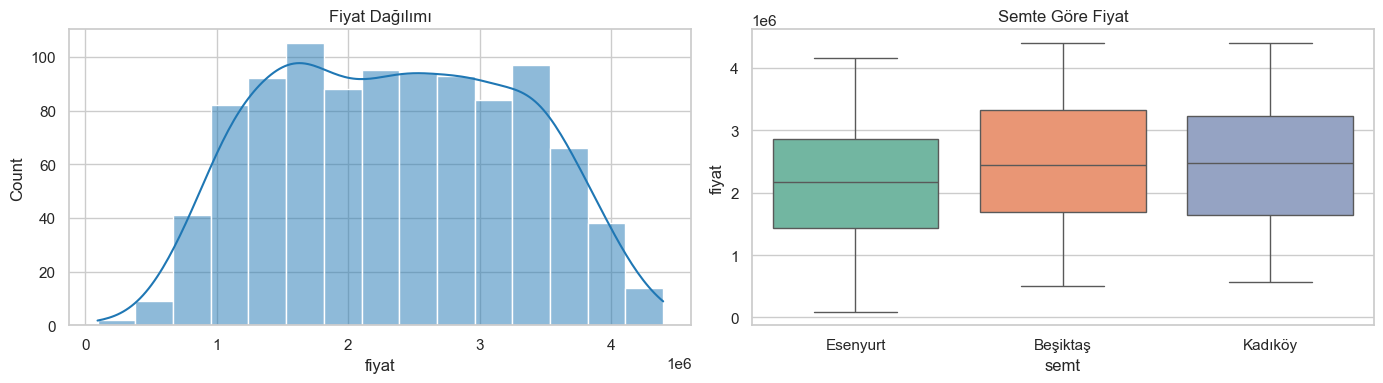

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["fiyat"], kde=True, color="tab:blue", ax=ax[0]); ax[0].set_title("Fiyat Dağılımı")
sns.boxplot(data=df, x="semt", y="fiyat", hue="semt", palette="Set2", ax=ax[1]); ax[1].set_title("Semte Göre Fiyat")
plt.tight_layout(); plt.show()

**Yorum:** Fiyat yaklaşık normal dağılımlı. Beşiktaş > Kadıköy > Esenyurt sıralaması, ürettiğimiz semt etkisiyle uyumlu.

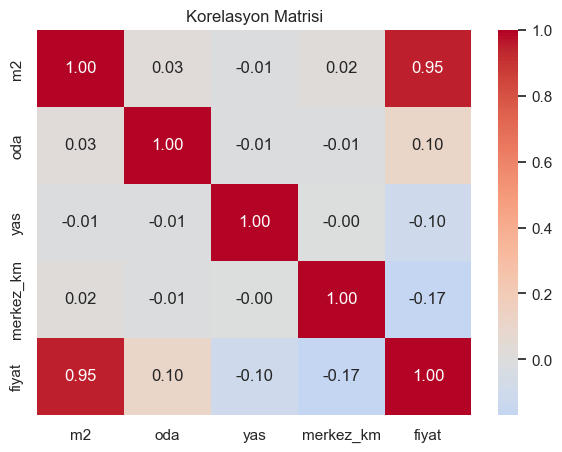

In [6]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasyon Matrisi"); plt.show()

**Yorum:** `m2` fiyatla en güçlü pozitif ilişkiye sahip; `merkez_km` ve `yas` negatif. Bağımsız değişkenler arasında yüksek korelasyon yok → çoklu doğrusallık beklemiyoruz.

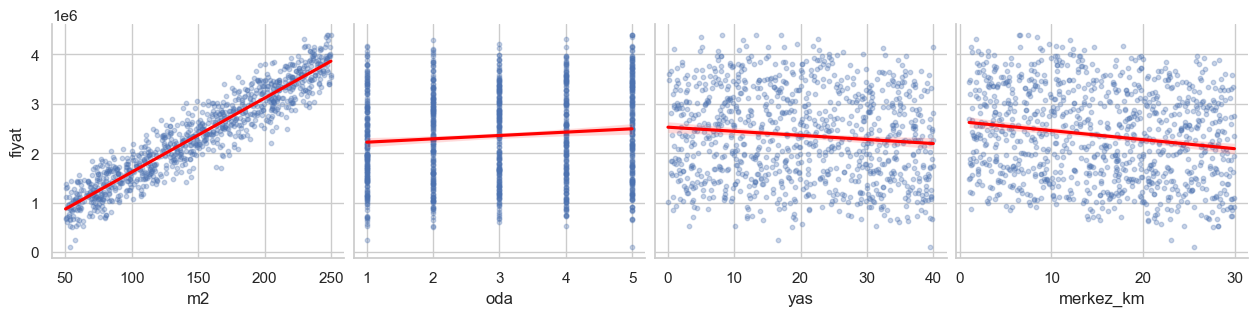

In [7]:
sns.pairplot(df, x_vars=["m2", "oda", "yas", "merkez_km"], y_vars="fiyat", kind="reg",
             height=3.2, plot_kws={"scatter_kws": {"alpha": 0.3, "s": 10}, "line_kws": {"color": "red"}})
plt.show()

**Yorum:** Her değişken fiyatla yaklaşık **doğrusal** ilişkide → doğrusallık varsayımı makul.

## 4. Train / Test Ayrımı
⚠️ Ön işlemeden **önce** ayırıyoruz.

In [8]:
X = df.drop(columns="fiyat")
y = df["fiyat"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (800, 5)  Test: (200, 5)


## 5. Yol 1 — scikit-learn Pipeline (önerilen)
- Sayısal: eksikleri medyanla doldur
- Kategorik (`semt`): One-Hot Encoding (`drop="first"` → kukla değişken tuzağını önler)

Katsayıları "TL / birim" olarak yorumlayabilmek için ölçekleme yapmıyoruz.

In [9]:
sayisal = ["m2", "oda", "yas", "merkez_km"]
kategorik = ["semt"]

on_isleme = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), sayisal),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), kategorik),
])
model = Pipeline([("on_isleme", on_isleme), ("reg", LinearRegression())])
model.fit(X_train, y_train)   # pipeline SADECE train'e fit edilir

sonuc = []
for ad, Xs, ys in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    p = model.predict(Xs)
    sonuc.append({"Set": ad, "MAE": mean_absolute_error(ys, p),
                  "RMSE": np.sqrt(mean_squared_error(ys, p)), "R²": r2_score(ys, p)})
pd.DataFrame(sonuc).set_index("Set").round(3)

,MAE,RMSE,R²
Set,,,
Train,117764.166,148532.052,0.974
Test,119752.899,150192.387,0.973


**Yorum:** Train ve Test R² değerleri birbirine çok yakınsa model **overfitting yapmıyor** demektir. RMSE değeri, eklediğimiz gürültünün standart sapmasına (150.000) yakın çıkmalı — model açıklanabilir olan her şeyi yakalamış demektir.

In [10]:
isimler = model.named_steps["on_isleme"].get_feature_names_out()
gercek = {"num__m2": 15_000, "num__oda": 50_000, "num__yas": -8_000, "num__merkez_km": -20_000,
          "cat__semt_Esenyurt": -300_000, "cat__semt_Kadıköy": -100_000}   # referans: Beşiktaş
katsayi = pd.DataFrame({"Tahmin": model.named_steps["reg"].coef_, "Gerçek": pd.Series(gercek)}, index=isimler)
print("Sabit (β0):", round(model.named_steps["reg"].intercept_))
katsayi.round(0)

Sabit (β0): 606845


,Tahmin,Gerçek
num__m2,14984.0,15000
num__oda,49298.0,50000
num__yas,-8125.0,-8000
num__merkez_km,-20894.0,-20000
cat__semt_Esenyurt,-383334.0,-300000
cat__semt_Kadıköy,-99390.0,-100000


**Yorum:** Model, gerçek katsayılara çok yakın değerler buluyor.
- `semt` için referans kategori alfabetik ilk olan **Beşiktaş**'tır; `semt_Kadıköy ≈ -100.000` "aynı özellikteki ev Kadıköy'de Beşiktaş'tan ~100 bin TL ucuz" demektir.

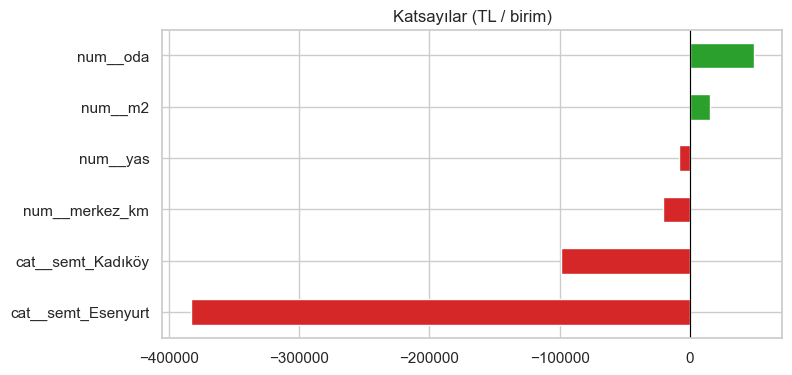

In [11]:
katsayi["Tahmin"].sort_values().plot.barh(figsize=(8, 4), color=["tab:red" if v < 0 else "tab:green" for v in katsayi["Tahmin"].sort_values()])
plt.title("Katsayılar (TL / birim)"); plt.axvline(0, color="black", lw=0.8); plt.show()

> Not: Bu grafik birimleri farklı değişkenleri karşılaştırır; **önem sıralaması** için değişkenleri `StandardScaler` ile ölçekleyip standart katsayılara bakmak gerekir.

In [12]:
yeni_ev = pd.DataFrame([{"m2": 120, "oda": 3, "yas": 10, "merkez_km": 5, "semt": "Kadıköy"}])
print(f"Tahmini fiyat: {model.predict(yeni_ev)[0]:,.0f} TL")

Tahmini fiyat: 2,267,702 TL


**Yorum:** Eğitilmiş pipeline ham veriyi alır; ön işlemeyi kendisi yapar. Yayına alırken tek bir nesne yeterlidir.

## 6. Artık (Residual) Analizi — Varsayım Kontrolü

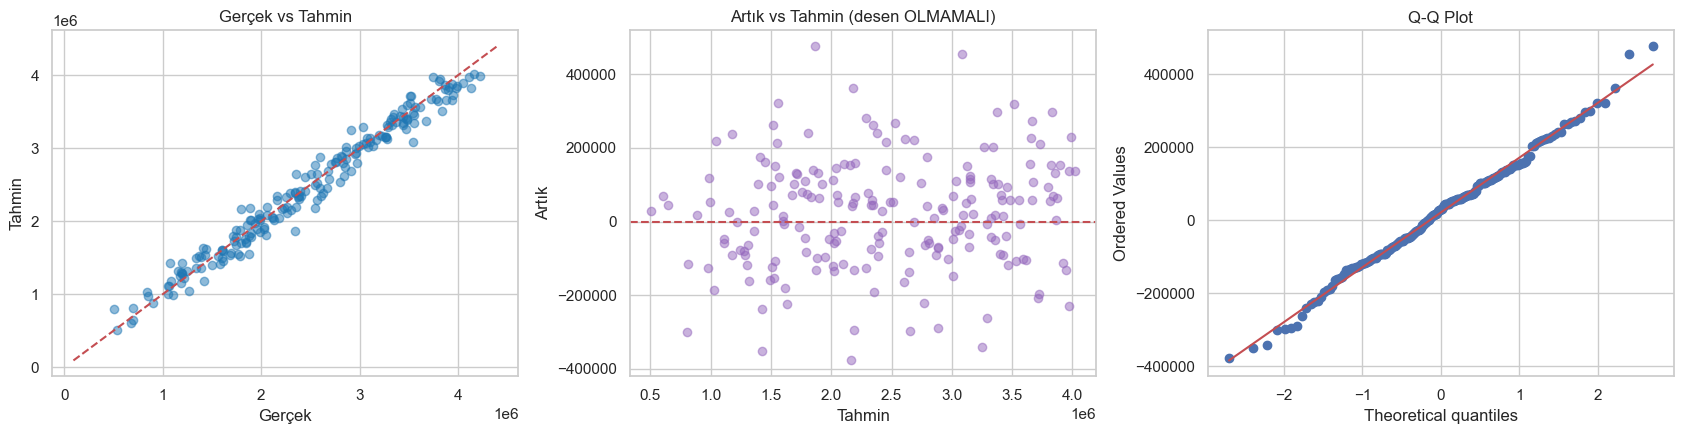

In [13]:
y_pred = model.predict(X_test)
artik = y_test - y_pred

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y_test, y_pred, alpha=0.5, color="tab:blue")
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set(title="Gerçek vs Tahmin", xlabel="Gerçek", ylabel="Tahmin")

ax[1].scatter(y_pred, artik, alpha=0.5, color="tab:purple"); ax[1].axhline(0, color="r", ls="--")
ax[1].set(title="Artık vs Tahmin (desen OLMAMALI)", xlabel="Tahmin", ylabel="Artık")

stats.probplot(artik, dist="norm", plot=ax[2]); ax[2].set_title("Q-Q Plot")
plt.tight_layout(); plt.show()

**Yorum:**
- **Gerçek vs Tahmin:** Noktalar kırmızı çizgi etrafında → iyi tahmin.
- **Artık vs Tahmin:** Sıfır etrafında rastgele, huni şekli yok → **sabit varyans** sağlanıyor.
- **Q-Q Plot:** Noktalar çizgi üzerinde → artıklar **normal dağılımlı**.

## 7. Yol 2 — statsmodels ile İstatistiksel Analiz
scikit-learn tahmine odaklanır; **"hangi değişken istatistiksel olarak anlamlı?"** sorusu için `statsmodels` kullanılır.

In [14]:
X_tr = X_train.copy()
X_tr["yas"] = X_tr["yas"].fillna(X_train["yas"].median())          # train medyanı
X_tr = pd.get_dummies(X_tr, columns=["semt"], drop_first=True, dtype=float)

ols = sm.OLS(y_train, sm.add_constant(X_tr)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                  fiyat   R-squared:                       0.974
Model:                            OLS   Adj. R-squared:                  0.974
Method:                 Least Squares   F-statistic:                     4984.
Date:                Sun, 04 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:44:26   Log-Likelihood:                -10662.
No. Observations:                 800   AIC:                         2.134e+04
Df Residuals:                     793   BIC:                         2.137e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          6.068e+05   2.45e+04     24.759

**Çıktı nasıl okunur?**

| Alan | Yorum |
|---|---|
| `R-squared` / `Adj. R-squared` | Açıklanan varyans; Adj. R² gereksiz değişkenleri cezalandırır |
| `coef` | β katsayıları (sklearn ile aynı olmalı) |
| `P>|t|` | **< 0.05** → değişken anlamlı |
| `[0.025 0.975]` | %95 güven aralığı |
| `Durbin-Watson` | ≈ 2 → hatalar bağımsız |
| `Prob (F-statistic)` | < 0.05 → model bütün olarak anlamlı |

Burada tüm değişkenlerin p-değeri ≈ 0 olmalı (çünkü hepsi gerçekten etkili).

In [15]:
Xc = sm.add_constant(X_tr)
vif = pd.DataFrame({"degisken": Xc.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]})
vif[vif["degisken"] != "const"].round(2)

,degisken,VIF
1,m2,1.0
2,oda,1.0
3,yas,1.0
4,merkez_km,1.0
5,semt_Esenyurt,1.3
6,semt_Kadıköy,1.3


**Yorum:** Tüm VIF değerleri ≈ 1 → **çoklu doğrusallık yok**. VIF > 5–10 olsaydı ilgili değişkeni çıkarmayı veya Ridge regresyonu düşünürdük.

## 8. Yol 3 — Sıfırdan NumPy: Normal Denklem
$$\boldsymbol{\beta} = (X^TX)^{-1}X^Ty$$

In [16]:
Xn = X_tr.values
yn = y_train.values

Xb = np.c_[np.ones(len(Xn)), Xn]                 # β0 için 1'lerden oluşan sütun
beta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ yn
pd.Series(beta, index=["sabit"] + list(X_tr.columns)).round(0)

sabit            606845.0
m2                14984.0
oda               49298.0
yas               -8125.0
merkez_km        -20894.0
semt_Esenyurt   -383334.0
semt_Kadıköy     -99390.0
dtype: float64

**Yorum:** Sonuçlar `LinearRegression` ve `statsmodels` ile birebir aynı — kütüphaneler arka planda bu formülü (veya sayısal olarak daha kararlı bir versiyonunu) kullanır.

## 9. Yol 4 — Sıfırdan NumPy: Gradyan İnişi
MSE'nin türevi: $\nabla = \frac{2}{n}X^T(X\beta - y)$, güncelleme: $\beta \leftarrow \beta - \eta\nabla$

sabit            606845.0
m2                14984.0
oda               49298.0
yas               -8125.0
merkez_km        -20894.0
semt_Esenyurt   -383334.0
semt_Kadıköy     -99390.0
dtype: float64


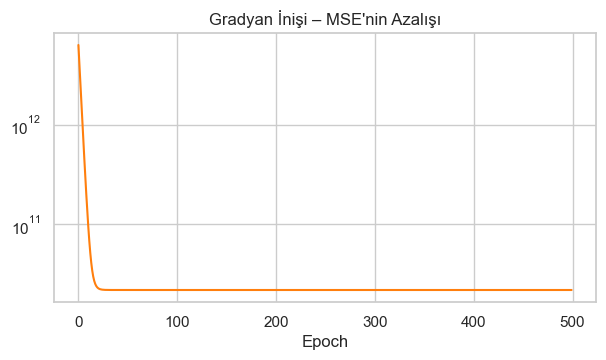

In [17]:
mu, sd = Xn.mean(0), Xn.std(0)
Xs = np.c_[np.ones(len(Xn)), (Xn - mu) / sd]     # GD için ölçekleme şart
w = np.zeros(Xs.shape[1]); lr = 0.1
kayip = []

for epoch in range(500):
    hata = Xs @ w - yn
    kayip.append(np.mean(hata ** 2))
    w -= lr * (2 / len(yn)) * Xs.T @ hata

# Ölçeklenmiş katsayıları orijinal birime çevir
b_orj = w[1:] / sd
b0_orj = w[0] - np.sum(w[1:] * mu / sd)
print(pd.Series(np.r_[b0_orj, b_orj], index=["sabit"] + list(X_tr.columns)).round(0))

plt.figure(figsize=(7, 3.5)); plt.plot(kayip, color="tab:orange")
plt.yscale("log"); plt.title("Gradyan İnişi – MSE'nin Azalışı"); plt.xlabel("Epoch"); plt.show()

**Yorum:** Kayıp birkaç düzine epoch içinde hızla düşüp sabitleniyor; bulunan katsayılar normal denklemle aynı.

## Özet
### Q&A
- **Çoklu lineer regresyon nedir?** Birden fazla değişkenin doğrusal kombinasyonuyla sürekli bir hedefi tahmin eden modeldir.
- **Nasıl kodlanır?** Pratikte `Pipeline + LinearRegression`; istatistiksel çıkarım için `statsmodels.OLS`; mantığı anlamak için NumPy (normal denklem / gradyan inişi).
### Data Analysis Key Findings
- Model, gerçek katsayıları (15.000 TL/m², 50.000 TL/oda, −8.000 TL/yaş, −20.000 TL/km) yüksek doğrulukla geri buldu; train ve test R² değerleri birbirine yakın.
- Artık grafikleri ve VIF değerleri, modelin tüm varsayımlarının sağlandığını gösteriyor.
### Insights or Next Steps
- Gerçek veride ilişkiler doğrusal olmayabilir → **02_Regresyon_Modelleri** notebook'unda Ridge/Lasso, polinom ve ağaç modellerini karşılaştırın.

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
diabates=load_diabetes()
X=diabates.data
y=diabates.target

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
pipeline=Pipeline([
    ('scaler',StandardScaler()),
    ('lin_reg',LinearRegression())
])
pipeline.fit(X_train,y_train)
y_pred=pipeline.predict(X_test)
mse=mean_squared_error(y_true=y_test,y_pred=y_pred)
r2=r2_score(y_test,y_pred)

print(f'mse:{mse:.2f}')
print(f'r2:{r2:.2%}')
print(f'sabit değer(intercept):{pipeline[-1].intercept_:.2f}')
print(f'Eğim katsayıları (coefficients):{pipeline[-1].coef_}')

mse:2900.19
r2:45.26%
sabit değer(intercept):153.74
Eğim katsayıları (coefficients):[  1.75375799 -11.51180908  25.60712144  16.82887167 -44.44885564
  24.64095356   7.67697768  13.1387839   35.16119521   2.35136365]


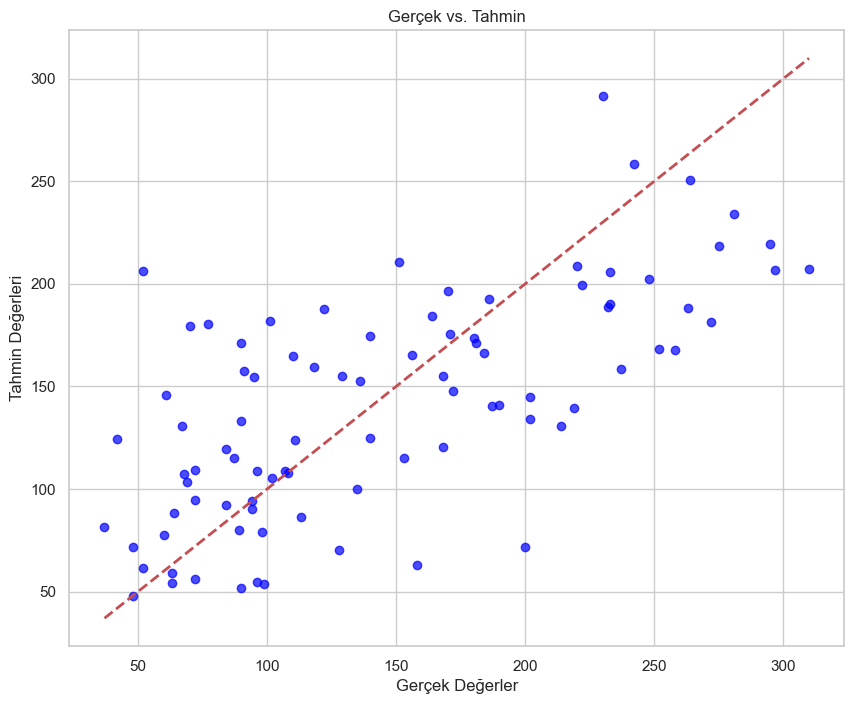

In [34]:
plt.figure(figsize=(10,8))
plt.scatter(y_test, y_pred, alpha=0.7, color="blue")
plt.plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2
)
plt.xlabel("Gerçek Değerler")
plt.ylabel("Tahmin Değerleri")
plt.title("Gerçek vs. Tahmin")
plt.show()

In [35]:
import numpy as np
from sklearn.linear_model import LinearRegression

# metrekare, oda_sayisi
X = np.array([[50, 1], [70, 2], [90, 3], [120, 3], [150, 4]])
y = np.array([150000, 220000, 280000, 350000, 450000])  # fiyat

# 1. Modeli oluşturma ve eğitme
model = LinearRegression()
model.fit(X, y)

# 2. 100m² ve 3 oda için tahmin girdisi (2 boyutlu dizi formatında olmalı)
yeni_ev = np.array([[100, 3]])

# 3. Tahmin yapma
tahmin = model.predict(yeni_ev)

print(f"Tahmini Fiyat: {tahmin[0]:.2f} TL")

Tahmini Fiyat: 306829.27 TL


In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Veri üretimi
X = np.random.rand(100, 2)
coef = np.array([3, 5])
y = 0 + np.dot(X, coef)


plt.show()

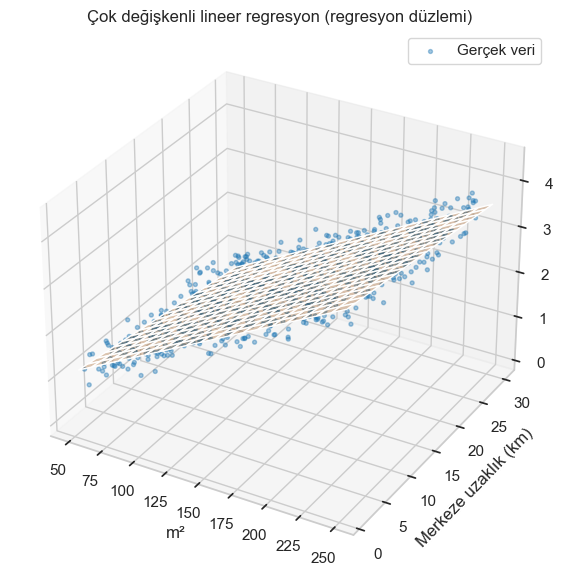

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1) Sadece 2 özellik seç (3B grafikte en fazla 2 X ekseni olabilir)
ozellikler = ["m2", "merkez_km"]
X2 = df[ozellikler]
y2 = df["fiyat"]

lin_reg = LinearRegression()
lin_reg.fit(X2, y2)

# 2) Izgarayı verinin gerçek aralığından oluştur
x1, x2 = np.meshgrid(np.linspace(X2["m2"].min(), X2["m2"].max(), 20),
                     np.linspace(X2["merkez_km"].min(), X2["merkez_km"].max(), 20))

grid = pd.DataFrame(np.c_[x1.flatten(), x2.flatten()], columns=ozellikler)  # flatten() parantezli!
y_pred = lin_reg.predict(grid)

# 3) 3B eksen oluştur ve çiz
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection="3d")
ax.scatter(X2["m2"], X2["merkez_km"], y2, c="tab:blue", s=8, alpha=0.4, label="Gerçek veri")
ax.plot_surface(x1, x2, y_pred.reshape(x1.shape), alpha=0.3, color="tab:orange")

ax.set_xlabel("m²"); ax.set_ylabel("Merkeze uzaklık (km)"); ax.set_zlabel("Fiyat")
plt.title("Çok değişkenli lineer regresyon (regresyon düzlemi)")
plt.legend(); plt.show()


In [54]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True)
df = data.frame

# 1. Hedef değişkeni hariç tutarak sadece öznitelikleri seç
features = [col for col in df.columns if col != 'MedHouseVal']
# veya doğrudan: features = data.feature_names

# 2. Korelasyon matrisini hesapla
corr_matrix = df[features].corr()

# 3. Korelasyonu |0.7|'den yüksek olan (i < j) çiftleri bul ve yazdır
threshold = 0.7
n = len(features)

for i in range(n):
    for j in range(i + 1, n):  # i < j şartı ile tekrarı ve köşegeni engeller
        feat_i = features[i]
        feat_j = features[j]
        corr_val = corr_matrix.loc[feat_i, feat_j]
        
        if abs(corr_val) > threshold:
            print(f"{feat_i} - {feat_j}: {corr_val:.4f}")

AveRooms - AveBedrms: 0.8476
Latitude - Longitude: -0.9247


In [55]:
import pandas as pd
import numpy as np

# 1. Elimizdeki Özellik İsimleri (feature_names)
ozellikler = ['Oda_Sayisi', 'Bina_Yasi', 'Merkeze_Uzaklik', 'Gelir']

# 2. Modelin Eğitildikten Sonra Bulduğu Katsayılar (coef)
# (Örnek: Gelir arttıkça fiyat artar, bina yaşı arttıkça fiyat çok düşer vb.)
katsayilar = np.array([0.15, -0.82, -0.05, 1.40])

# 3. Adım: Mutlak değerlerini hesaplayalım
mutlak_katsayilar = np.abs(katsayilar)
print("Mutlak Değerler:", mutlak_katsayilar)
# Çıktı: [0.15, 0.82, 0.05, 1.40]

# 4. Adım: Hepsini bir DataFrame'de birleştirelim
df = pd.DataFrame({
    'feature': ozellikler,
    'coef': katsayilar,
    'abs_coef': mutlak_katsayilar
})

print("\n--- İlk Ham Tablo ---")
display(df)


Mutlak Değerler: [0.15 0.82 0.05 1.4 ]

--- İlk Ham Tablo ---


,feature,coef,abs_coef
0,Oda_Sayisi,0.15,0.15
1,Bina_Yasi,-0.82,0.82
2,Merkeze_Uzaklik,-0.05,0.05
3,Gelir,1.40,1.40


In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

# 1. Veri setini yükle
housing = fetch_california_housing(as_frame=True)
X = housing.data


def find_high_correlation_pairs(df, threshold=0.7):
    """
    Bir DataFrame'deki bağımsız değişkenler arasındaki yüksek korelasyonlu çiftleri bulur.
    
    Parametreler:
        df (pd.DataFrame): Özellikler matrisi (X)
        threshold (float): Eşik değer (örn: 0.70 veya 0.80)
        
    Döndürür:
        pd.DataFrame: ['Feature 1', 'Feature 2', 'Correlation', 'Abs_Correlation'] sütunları
    """
    # Adım A: Korelasyon matrisini hesapla
    corr_matrix = df.corr()
    
    # Adım B: Üst üçgen maskesi oluştur (k=1 diyagonali hariç tutar)
    # True olan yerler sadece matrisin üst tarafı (ayna etkisini ve kendisiyle korelasyonu eler)
    upper_tri_mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    
    # Adım C: Sadece üst üçgendeki değerleri al, geri kalanı NaN yap
    upper_corr = corr_matrix.where(upper_tri_mask)
    
    # Adım D: Tabloyu düzleştir (unpivot / stack) ve sütun isimlerini düzenle
    pairs = upper_corr.stack().reset_index()
    pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
    
    # Adım E: Mutlak değer sütunu ekle (çünkü -0.85 de çok güçlü bir ilişkidir!)
    pairs['Abs_Correlation'] = pairs['Correlation'].abs()
    
    # Adım F: Eşik değerine göre filtrele ve büyükten küçüğe sırala
    high_corr_df = pairs[pairs['Abs_Correlation'] >= threshold].sort_values(
        by='Abs_Correlation', ascending=False
    ).reset_index(drop=True)
    
    return high_corr_df


# --- Fonksiyonu Çalıştıralım ---
# Eşik değerini 0.70 (güçlü ilişki) alıyoruz
yuksek_korelasyonlar = find_high_correlation_pairs(X, threshold=0.70)

print(f"Eşik Değer (0.70) Üzerindeki Özellik Çiftleri Sayısı: {len(yuksek_korelasyonlar)}")
display(yuksek_korelasyonlar)


Eşik Değer (0.70) Üzerindeki Özellik Çiftleri Sayısı: 2


,Feature 1,Feature 2,Correlation,Abs_Correlation
0,Latitude,Longitude,-0.924664,0.924664
1,AveRooms,AveBedrms,0.847621,0.847621
